In [8]:
import os
import random 
import numpy as np
import pandas as pd
import polars as pl
import zarr
import dask.array as da
import madi_utils
from importlib import reload
import matplotlib.pyplot as plt
reload(madi_utils)
from align_3d import align_object_standard
from aicsshparam.shtools import get_mesh_from_image
reload(madi_utils)

<module 'madi_utils' from '/net/beliveau/vol1/home/msforman/msf_project/lightsheet-analysis-pipeline/scripts/madi_utils.py'>

In [ ]:
root = "/net/beliveau/vol2/instrument/E9.5_306/Zoom_306"
mask_path = f"{root}/dataset_fused_masks_copy.zarr"
image_path = f"{root}/dataset_fused_rechunked_blocks_attn_ax0.zarr"
bbox_path = f"{root}/dataset_fused_features_NEWCOLUMNS_bboxes.csv"
df_path = f"{root}/dataset_fused_features_NEWCOLUMNS.csv"

dir_save = f"{root}/figures"

channels = [0, 1, 2]
mask_da, image_arrays = madi_utils.load_data(mask_path, image_path, channels)

print(f"Mask shape: {mask_da.shape}")
print(f"Available channels: {list(image_arrays.keys())}")

Mask shape: (4315, 7626, 5475)
Available channels: [0, 1, 2]


    Centroid_Z   Centroid_Y   Centroid_X
0  2908.348109  5728.242145  1098.039023
Max projection over z


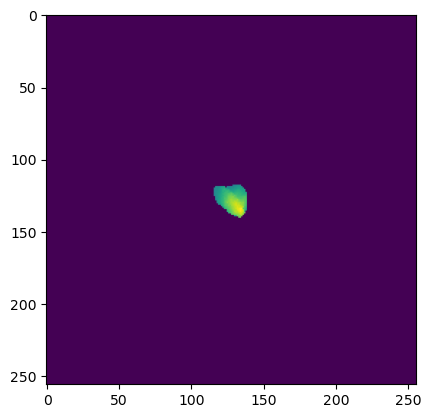

Max projection over y


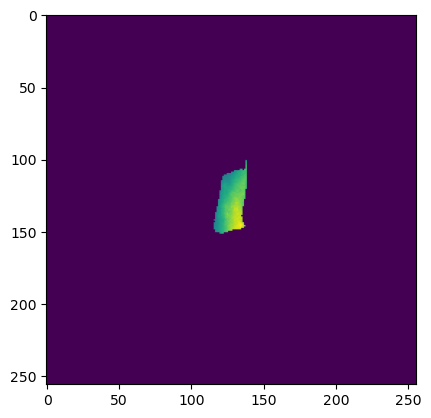

Max projection over x


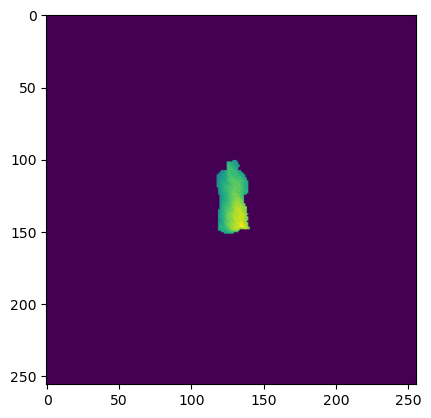

In [21]:
label = 491516
# lazy load filter for label from main csv
df = pl.scan_csv(df_path)
query = (
    df.filter(pl.col("Nuclear_ID") == label)
    .select(['Centroid_Z', 'Centroid_Y', 'Centroid_X'])
    .collect()
)
cell_df = query.to_pandas()
print(cell_df)
# find object bounding box
df_bboxes = pd.read_csv(bbox_path)

# comment out from here to next "group_items = list(grouped)" line, and comment back in the rest to load random object
df_bboxes = madi_utils.add_chunk_indices(df_bboxes, mask_da.chunks)
df_bboxes = df_bboxes[df_bboxes["label"] == label]
zstart, zend, ystart, yend, xstart, xend = madi_utils.get_bounds(df_bboxes)


# crop to mask roi
crop_size = 128 * 2
half = crop_size // 2
arr = image_arrays[2]

x = int(cell_df['Centroid_X'].values[0])
y = int(cell_df['Centroid_Y'].values[0])
z = int(cell_df['Centroid_Z'].values[0])
obj_id = label
z_dim, y_dim, x_dim = arr.shape


x1, x2 = max(0, x - half), min(x_dim, x + half)
y1, y2 = max(0, y - half), min(y_dim, y + half) 
z1, z2 = max(0, z - half), min(z_dim, z + half)


binary_mask = mask_da[z1:z2, y1:y2, x1:x2] == obj_id
img_crop = arr[z1:z2, y1:y2, x1:x2]

img_crop = np.where(binary_mask, img_crop, 0) # crop the array to the mask
for i in range(0, 3):
    if i == 0:
        print("Max projection over z")
    elif i == 1:
        print("Max projection over y")
    else:
        print("Max projection over x")
    plt.imshow(np.max(img_crop, axis=i))
    plt.show()

aligned_standard, original_list = [], []
grouped = df_bboxes.groupby(["cz", "cy", "cx"], sort=False)
group_items = list(grouped)



# RANDOM SELECTED OBJECT -- UNCOMMENT TO RUN
# n=1
# aligned_standard, original_list = [], []
# random.seed(123456)

# df_bboxes = madi_utils.add_chunk_indices(df_bboxes, mask_da.chunks)

# grouped = df_bboxes.groupby(["cz", "cy", "cx"], sort=False)
# group_items = list(grouped) 

# (cz, cy, cx), group_df = random.choice(group_items)
# labels = group_df["label"].astype(np.int64).tolist()

# zstart, zend, ystart, yend, xstart, xend = madi_utils.get_bounds(group_df)
# mask_roi = mask_da[zstart:zend, ystart:yend, xstart:xend]
# label = np.random.choice(labels, size=n)[0]


In [ ]:
print("Label: ", label)
# add original object to list
og_mesh, obj_image = madi_utils.get_object(label, mask_roi)
print(f"obj num bytes: {obj_image.nbytes}")
original_list.append((og_mesh, obj_image))

# add aligned object to list
aligned_image, _ = align_object_standard(obj_image, {})
aligned_mesh, _, _ = get_mesh_from_image(aligned_image)
aligned_standard.append((aligned_mesh, aligned_image))

Label:  491516
obj num bytes: 215832


In [ ]:
def plot_list(original_list, aligned_standard, obj_id):
    for og, std in zip(original_list, aligned_standard):
        madi_utils.plot_object(og, "Before Alignment", show_title=True)
        madi_utils.plot_object(std, "After Alignment", show_title=True)
        madi_utils.plot_reconstruction(obj_id, "Reconstruction", show_title=True)

def crop_max_proj(zarr_path, mask_path, centroid_z, centroid_y, centroid_x, crop_size=128):
plot_list(original_list, aligned_standard, 491516)

shape: (1, 578)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ shcoeffs_ ┆ shcoeffs_ ┆ shcoeffs_ ┆ shcoeffs_ ┆ … ┆ shcoeffs_ ┆ shcoeffs_ ┆ shcoeffs_ ┆ shcoeffs │
│ L0M0C     ┆ L0M1C     ┆ L0M2C     ┆ L0M3C     ┆   ┆ L16M13S   ┆ L16M14S   ┆ L16M15S   ┆ _L16M16S │
│ ---       ┆ ---       ┆ ---       ┆ ---       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ ---      │
│ f64       ┆ f64       ┆ f64       ┆ f64       ┆   ┆ f64       ┆ f64       ┆ f64       ┆ f64      │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 11.643944 ┆ 0.0       ┆ 0.0       ┆ 0.0       ┆ … ┆ 0.003215  ┆ 0.012509  ┆ -0.024911 ┆ 0.010533 │
└───────────┴───────────┴───────────┴───────────┴───┴───────────┴───────────┴───────────┴──────────┘
